# 🧪 Notebook 13 — Sample-Based Quantum Diagonalization

> **Module:** Quantum Computing for Computational Chemistry\
> **Level:** Advanced\
> **Estimated time:** 90 min\
> **Prerequisites:** UCC/UCCSD, molecular Hamiltonians, computational-basis sampling, and selected-CI concepts

---

## 📌 Overview

This notebook implements Sample-based Quantum Diagonalization (SQD) to compute the ground state of H₄.

## 🎯 Learning objectives

By the end of this notebook, you should be able to:

- Construct UCCSD singles and doubles amplitudes.
- Prepare and sample a correlated molecular state.
- Select configurations from computational-basis samples.
- Evaluate the selected subspace against an FCI benchmark.

## 🔑 Key concepts

`SQD` · `UCCSD` · `anti-Hermitian generator` · `configuration selection` · `shot sampling` · `selected-CI`

## 🧩 Structure

1. H₄ molecular Hamiltonian
2. UCCSD amplitudes and generator
3. Exact correlated state
4. Quantum circuit sampling
5. Selected-CI energy and convergence

## 📚 Resources

- PySCF, OpenFermion, Qiskit, and `qiskit_addon_sqd` documentation
- Previous notebook: `adapt_vqe.ipynb`

### ⏱️ Expected outcome

You will construct a sampled configuration subspace method to compute the ground state energy of H₄.

# Sample-based quantum diagonalization

Sample-based quantum diagonalization (SQD) uses bit strings sampled from a quantum circuit to define a compact configuration subspace. The Hamiltonian is then solved classically in that subspace. This notebook builds the workflow for a linear H4 chain in the STO-3G basis:

1. Compute Hartree-Fock and FCI reference energies.
2. Build a UCCSD-inspired fermionic excitation operator.
3. Prepare and sample a correlated state on eight qubits.
4. Select sampled configurations and solve the resulting SCI problem.

The central trade-off is that the sampled subspace is much smaller than the full $2^8$-dimensional Fock space, while still retaining configurations important to the correlated state.

In [26]:
import numpy as np
import qiskit
import openfermion
import pyscf
from networkx.algorithms.bipartite.basic import density

## Molecular Hamiltonian

In [27]:
# H4 molecule
from pyscf import gto, scf

# Build molecule
d=2.0
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 1*d)],
          ["H", (0.0, 0.0, 2*d)],
          ["H", (0.0, 0.0, 3*d)]
          ],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.57561647670187


np.float64(-1.5756164767018652)

The molecule is a linear chain of four hydrogen atoms with spacing $d=2.0$ Angstrom. In the STO-3G basis there are four spatial orbitals, or eight spin orbitals, so the qubit representation uses eight qubits. RHF provides the mean-field reference, while the displayed FCI calculation supplies a classical benchmark for the correlated ground-state energy.

### FCI reference ground state

In [28]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
fci_energy, ci = cisolver.kernel()
print("FCI energy:", fci_energy)

FCI energy: -1.8977806459898718


In [29]:
tol_ampl = 1e-4

from pyscf.fci import cistring
mc = cisolver

ncas = mc.norb
nelec = mc.nelec

# determinants α i β (representats com enters amb bits d’ocupació)
na, nb = nelec
alpha_det = cistring.make_strings(range(ncas), na)
beta_det = cistring.make_strings(range(ncas), nb)


def interleave_bits(a, b, ncas):
    """Return interleaved occupation string (αβ αβ ...)"""
    a_bits = [(a >> i) & 1 for i in range(ncas)]
    b_bits = [(b >> i) & 1 for i in range(ncas)]
    inter = []
    for i in reversed(range(ncas)):
        inter.append(str(a_bits[i]))
        inter.append(str(b_bits[i]))
    return ''.join(inter)[::-1]

print('\namplitudes FCI')
for i, a in enumerate(alpha_det):
    for j, b in enumerate(beta_det):
        amp = mc.ci[i, j]
        if amp**2 > tol_ampl:
            # print(f"α={format(a, f'0{ncas}b')}  β={format(b, f'0{ncas}b')}  coef={amp:+.6f}")
            cfg = interleave_bits(a, b, ncas)
            print(f"{cfg}   {amp:+.6f}  ({amp**2:.6f}) ")


amplitudes FCI
11110000   +0.694100  (0.481775) 
01111000   -0.018033  (0.000325) 
11010010   +0.013777  (0.000190) 
01011010   +0.074107  (0.005492) 
11001100   -0.388924  (0.151262) 
01100110   -0.181096  (0.032796) 
10110100   -0.018033  (0.000325) 
00111100   -0.114150  (0.013030) 
10010110   -0.255203  (0.065128) 
00011110   +0.030608  (0.000937) 
11100001   +0.013777  (0.000190) 
01101001   -0.255203  (0.065128) 
11000011   -0.107524  (0.011561) 
01001011   -0.032817  (0.001077) 
10011001   -0.181096  (0.032796) 
00110011   -0.251266  (0.063134) 
10100101   +0.074107  (0.005492) 
00101101   +0.030608  (0.000937) 
10000111   -0.032817  (0.001077) 
00001111   +0.259514  (0.067347) 


### Build second quantization Hamiltonian from electronic integrals

In [30]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
# nuclear
print(e_nuc)

[[-1.13379714e+00  4.59558098e-17  9.24693961e-02 -1.51622088e-16]
 [ 1.15536374e-16 -1.04226825e+00 -4.65247684e-16 -7.41977398e-02]
 [ 9.24693961e-02 -5.60145542e-16 -9.78602165e-01 -3.41894381e-16]
 [-7.06798886e-17 -7.41977398e-02 -3.87119704e-16 -9.67108698e-01]]
[[[[ 3.50481811e-01 -3.33066907e-16 -5.76182543e-02 -1.21430643e-17]
   [-2.91433544e-16  1.64643593e-01 -9.02056208e-17  3.03991509e-02]
   [-5.76182543e-02 -7.63278329e-17  1.27781482e-01  2.32452946e-16]
   [ 6.93889390e-18  3.03991509e-02  2.39391840e-16  1.23346862e-01]]

  [[-2.91433544e-16  1.64643593e-01 -9.02056208e-17  3.03991509e-02]
   [ 3.19106671e-01  2.77555756e-16  1.74272684e-02  6.93889390e-17]
   [-4.16333634e-17  6.97056778e-02 -4.85722573e-17 -1.03951062e-01]
   [ 5.98408006e-02 -6.93889390e-18 -1.29023423e-01 -3.46944695e-18]]

  [[-5.76182543e-02 -7.63278329e-17  1.27781482e-01  2.32452946e-16]
   [-4.16333634e-17  6.97056778e-02 -4.85722573e-17 -1.03951062e-01]
   [ 3.22145549e-01 -8.32667268e-17  

### Build the second quantization Hamiltonian

In [31]:
from openfermion import InteractionOperator, jordan_wigner
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5*eri_so)


## Build UCC ansatz


### Reference state

The reference state occupies spin orbitals 0 through 3, represented by the creation string `0^ 1^ 2^ 3^`

In [32]:
from openfermion import FermionOperator
# a b a b a b
state = FermionOperator('0^ 1^ 2^ 3^')

UCCSD includes all single and double excitations from the occupied orbitals into the virtual orbitals. For this eight-spin-orbital example, the amplitudes are small but numerous enough to distribute probability over many determinants.

In [33]:
from pyscf import gto, scf, cc

mycc = cc.UCCSD(mf)
mycc.kernel()

E(UCCSD) = -1.916086117177892  E_corr = -0.3404696404760266


(np.float64(-0.3404696404760266),
 (array([[ 1.24424414e-02,  8.02218942e-16],
         [-1.26995954e-15,  6.84360061e-03]]),
  array([[ 1.24424414e-02, -8.01680394e-16],
         [ 1.22885186e-15,  6.84360061e-03]])),
 (array([[[[ 0.       ,  0.       ],
           [ 0.       ,  0.       ]],
  
          [[ 0.       ,  0.1339747],
           [-0.1339747,  0.       ]]],
  
  
         [[[ 0.       , -0.1339747],
           [ 0.1339747,  0.       ]],
  
          [[ 0.       ,  0.       ],
           [ 0.       ,  0.       ]]]]),
  array([[[[-1.37795221e-01, -7.74349814e-16],
           [-5.60927274e-16, -4.27542955e-01]],
  
          [[ 2.85920767e-16,  3.91155263e-01],
           [ 2.57180559e-01, -2.40428086e-16]]],
  
  
         [[[ 7.75692309e-16,  2.57180559e-01],
           [ 3.91155263e-01, -4.60725135e-16]],
  
          [[-6.31915798e-01,  9.03363081e-16],
           [ 4.63484926e-16, -1.28821479e-01]]]]),
  array([[[[ 0.       ,  0.       ],
           [ 0.       ,  0.     

The UCCSD amplitudes are separated into alpha, beta, and mixed-spin tensors. The printed shapes confirm two occupied and two virtual spatial orbitals, with doubles tensors carrying four orbital indices.

In [34]:
t1a, t1b = mycc.t1
t2a, t2ab, t2b = mycc.t2

In [35]:
print(t1a.shape)

(2, 2)


In [36]:
print(t1b.shape)

(2, 2)


In [37]:
print(t2a.shape)

(2, 2, 2, 2)


In [38]:
print(t2b.shape)


(2, 2, 2, 2)


In [39]:
print(t2ab.shape)

(2, 2, 2, 2)


## Building the UCC generator

Single excitations remove an electron from an occupied orbital $i$ and creates one in a virtual orbital $a$. The operator is weighted by the UCCSD amplitude $t_i^a$ and is included for both spin channels.

\begin{aligned}
T_1 =
\sum_{ia} t^{\alpha}_{i a}
a^\dagger_{a\alpha}a_{i\alpha}
+
\sum_{ia} t^{\beta}_{i a}
a^\dagger_{a\beta}a_{i\beta}
\end{aligned}

In [40]:
from openfermion import FermionOperator

T1 = FermionOperator()

nocc, nvir = t1a.shape
print('nocc:', nocc)
print('nvir:', nvir)

# Alpha singles
for i in range(nocc):
    for a in range(nvir):
        virt = nocc + a
        T1 += t1a[i, a] * FermionOperator(((2*virt, 1), (2*i, 0)))
        T1 += t1b[i, a] * FermionOperator(((2*virt+1, 1), (2*i+1, 0)))

T1

nocc: 2
nvir: 2


0.012442441378450088 [4^ 0] +
0.012442441378450412 [5^ 1] +
0.006843600606185176 [6^ 2] +
0.006843600606184826 [7^ 3]

The `T1` operator contains the four single-excitation terms for this system. OpenFermion labels creation with `^`; for example, `(4^ 0)` promotes an alpha electron from occupied spin orbital 0 to virtual spin orbital 4.

\begin{aligned}
T_2^{\alpha\alpha}
=
\frac{1}{4}
\sum_{ijab}
t^{\alpha\alpha}_{ijab}
a^\dagger_{a\alpha}
a^\dagger_{b\alpha}
a_{j\alpha}
a_{i\alpha}
\end{aligned}

\begin{aligned}
T_2^{\beta\beta}
=
\frac{1}{4}
\sum_{ijab}
t^{\beta\beta}_{ijab}
a^\dagger_{a\beta}
a^\dagger_{b\beta}
a_{j\beta}
a_{i\beta}
\end{aligned}

\begin{aligned}
T_2^{\alpha\beta} = \sum_{ijab}
t^{\alpha\beta}_{ijab}
a^\dagger_{a\alpha}
a^\dagger_{b\beta}
a_{j\beta}
a_{i\alpha}
\end{aligned}

In [41]:
T2aa = FermionOperator()
T2bb = FermionOperator()
T2ab = FermionOperator()

# Alpha-alpha doubles
for i in range(nocc):
    for j in range(nocc):
        for a in range(nvir):
            for b in range(nvir):

                virt_a = nocc + a
                virt_b = nocc + b
                # print(2*j, 2*i, 2*virt_a, 2*virt_b)

                T2aa += 0.25 * t2a[i, j, a, b] * FermionOperator(((2*virt_a, 1),
                                                                (2*virt_b, 1),
                                                                (2*j, 0),
                                                                (2*i, 0)))

                T2bb += 0.25 * t2b[i, j, a, b] * FermionOperator(((2*virt_a+1, 1),
                                                                (2*virt_b+1, 1),
                                                                (2*j+1, 0),
                                                                (2*i+1, 0)))

                T2ab += t2ab[i, j, a, b] * FermionOperator(((2 * virt_a, 1),
                                                            (2 * virt_b + 1, 1),
                                                            (2 * j + 1, 0),
                                                            (2 * i, 0)))


Double excitations promote two electrons simultaneously. Same-spin terms carry the conventional $1/4$ prefactor, while the mixed-spin term is stored separately. Combining these pieces gives the full cluster operator T.

\begin{aligned}
T=T_1+T_2^{\alpha\alpha} +T_2^{\beta\beta}+T_2^{\alpha\beta}
\end{aligned}


In [42]:
T = T1 + T2aa + T2bb + T2ab

## Anti-Hermitian generator

Unitary coupled-cluster evolution uses the anti-Hermitian generator $K=T-T^\dagger$. The exponential $e^K$ is unitary for anti-Hermitian generators, preserving the norm of the reference state.

In [43]:
from openfermion import hermitian_conjugated

K = T - hermitian_conjugated(T)

In [44]:
from openfermion import normal_ordered
def is_antihermitian(op):
    hermitian_part = normal_ordered(op + hermitian_conjugated(op))
    return len(hermitian_part.terms) == 0


print('is antihermitian?')
print('K : ', is_antihermitian(K))

is antihermitian?
K :  True


The explicit check confirms that $K$ is anti-Hermitian after normal ordering. The reference determinant is then re-created so the next cells can apply the full generator and compare the resulting correlated state with the Hartree-Fock state.

## Exact preparation of the correlated state

The next cell prepares de UCC state by applying $e^{K}$ operator to the reference determinant using sparse-matrix exponentiation. This is a classical stand-in for the excitation circuit and provides an ideal probability distribution against which the sampled circuit distribution can be compared.

In [45]:
from scipy.sparse.linalg import expm, expm_multiply
from openfermion import get_sparse_operator

vec_ref = get_sparse_operator(state, n_qubits=8)
print('norm:', (vec_ref.T.conj() @ vec_ref)[0, 0])

k_qubit = jordan_wigner(K)
sparse_op = get_sparse_operator(k_qubit, n_qubits=8)
vec_cc = expm_multiply(sparse_op, vec_ref)

print('norm:', (vec_cc.T.conj() @ vec_cc)[0, 0])


norm: (1+0j)
norm: (1+0j)


The norm remains one after applying $e^K$, as expected for a unitary transformation. `jordan_wigner(K)` maps the fermionic generator to qubit operators before sparse exponentiation.

### Check the exact UCC energy
the exact energy of the UCC can be calculated using the operators build in the previous cells. This energy is significantly higher than the FCI energy.

In [46]:
#energy
sparse_ha = get_sparse_operator(hamiltonian)
print('Energy HF: ', (vec_ref.T.conj() @ sparse_ha @ vec_ref)[0, 0].real)
print('Energy UCC', (vec_cc.T.conj() @ sparse_ha @ vec_cc)[0, 0].real)


Energy HF:  -1.5756164767018646
Energy UCC -1.8582158937193711


### Sampling configurations

The exact correlated state is converted into computational-basis probabilities $p_x=|\langle x|\psi\rangle|^2$. Configurations are sorted by probability and filtered by a small threshold. This produces the ideal selected configuration list used as a reference for the circuit-derived list.

00001111 0.29479503254614536
00110011 0.2128065765416938
11110000 0.19014569747053184
01101001 0.07062555845052755
10010110 0.07062555845052743
11001100 0.06675497713863776
01100110 0.030520131582880385
10011001 0.030520131582880385
00111100 0.00900598904772969
01011010 0.008290935991958688
10100101 0.008290935991958688
11000011 0.007407714317121758


Text(0, 0.5, 'Probability')

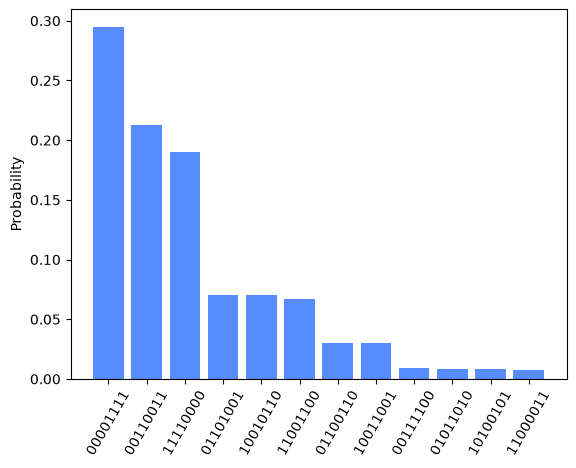

In [47]:
probs = np.abs(vec_cc.toarray()[:,0])**2
#print('sum squares: ', sum(probs))

def binary_strings(n, width):
    for i in range(n):
        yield format(i, f'0{width}b')[::-1] # revert to have the same order as qiskit


tol_ampl = 1e-4
prob_exact = {}
for b, p  in zip(binary_strings(2**8, 8), probs):
    if p > tol_ampl:
        prob_exact[b] = p

prob_ordered = dict(sorted(prob_exact.items(), key=lambda item: -item[1]))
for k, v in prob_ordered.items():
    print(k, v)

import matplotlib.pyplot as plt
plt.bar(prob_ordered.keys(), prob_ordered.values())
plt.xticks(rotation=60)
plt.ylabel('Probability')


### Preparation of CC ansatz in a quantum circuit
The circuit starts from the Hartree-Fock reference by applying $X$ gates to the occupied spin orbitals. Each Pauli term in the Jordan-Wigner image of $K$ is implemented with basis changes, a CNOT ladder, and an $R_z$ rotation.

In [48]:
from qiskit import QuantumCircuit

t_qubit = jordan_wigner(K)

# Build the ansatz
qc = QuantumCircuit(8)

# reference state
qc.x(0)
qc.x(1)
qc.x(2)
qc.x(3)

i_op = 0
for op, coef in t_qubit.terms.items():
    #continue

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    if len(op) > 0:
        qc.rz(2*coef.imag, op[0][0])

    for qubit, pauli in reversed(op[1:]):
        qc.cx(qubit, op[0][0])

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(-np.pi / 2, [qubit])

    qc.barrier()

qc.measure_all()
print('circuit depth: ', qc.depth())
#qc.draw('mpl')

circuit depth:  1002


The displayed depth is large because every mapped Pauli term is expanded into a separate basis-change and entangling sequence. This direct construction is useful pedagogically, but circuit optimization and compression are important for hardware implementations.

### Sampling the ansatz

00001111 0.3283
11110000 0.1684
00110011 0.1653
10010110 0.0812
01101001 0.0796
11001100 0.0465
01100110 0.0413
10011001 0.0413
01011010 0.0192
10100101 0.0164
00111100 0.0081
11000011 0.0042
00101101 0.0002


Text(0, 0.5, 'Probability')

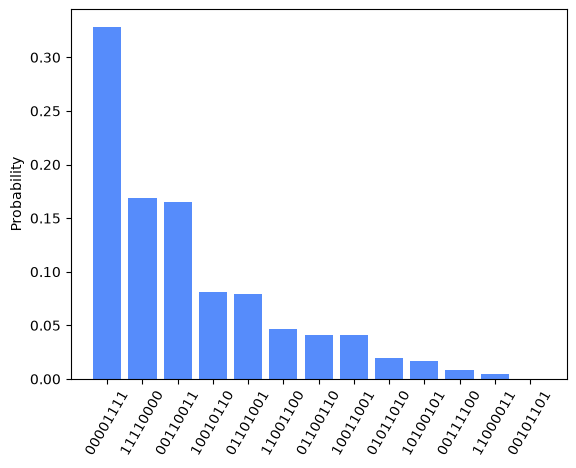

In [49]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()

result = sampler.run([qc], shots=10000).result()
counts = result[0].data.meas.get_counts()
shots = sum(counts.values())

counts_ordered = dict(sorted(counts.items(), key=lambda item: -item[1]))
for k, v in counts_ordered.items():
    print(k, v/shots)

import matplotlib.pyplot as plt
plt.bar(counts_ordered.keys(), [c/shots for c in counts_ordered.values()])
plt.xticks(rotation=60)
plt.ylabel('Probability')

The circuit histogram approximates the ideal probabilities with finite-shot sampling. Configurations with higher probability are more likely to be included in the selected subspace; rare configurations may be missed, which is the main statistical approximation in SQD.

## Selected-configuration diagonalization
We will use `qiskit_addon_sqd` to perform the selected-configuration fermionic diagonalization.

Here, `get_sci_energy` converts each sampled bit string into separate alpha and beta occupation patterns and calls `solve_fermion` on only those configurations. Adding the Hamiltonian constant restores the total molecular energy. Equal exact and circuit energies here indicate that the sampled circuit retained the configurations needed by this small example.

In [50]:
from qiskit_addon_sqd.fermion import solve_fermion

def get_sci_energy(configuration_list):

    up_list = []
    down_list = []
    for fock_vector in configuration_list:

        bitstring = ''.join(str(bit) for bit in fock_vector)

        up_str = ''.join(
            '0' if i % 2 == 0 else bit
            for i, bit in enumerate(bitstring)
        )

        down_str = ''.join(
            bit if i % 2 == 0 else '0'
            for i, bit in enumerate(bitstring)
        )

        up_list.append(int(up_str, 2))
        down_list.append(int(down_str, 2))

    up = np.array(up_list, dtype=np.uint32)
    down = np.array(down_list, dtype=np.uint32)

    inv = np.argsort((0, 2, 3, 1))
    # Hamiltonian absorbs 1/2 into the coefficients. To recover 2e integrals should be multiplied by 2
    two_body_tensor_restored = hamiltonian.two_body_tensor.transpose(inv) * 2


    energy_sci, coeffs_sci, avg_occs, spin = solve_fermion((up, down),
                                                           hamiltonian.one_body_tensor,
                                                           two_body_tensor_restored,
                                                           open_shell=False,
                                                           #spin_sq=0,
                                                           )

    return energy_sci + hamiltonian.constant # total energy

# exact calculation
configuration_list_exact = list(prob_ordered.keys()) # exact
print('Final energy exact  : ', get_sci_energy(configuration_list_exact))


# circuit calculation
configuration_list_circuit = list(counts_ordered.keys()) # circuit
print('Final energy circuit: ', get_sci_energy(configuration_list_circuit))


Final energy exact  :  -1.8977806459872237
Final energy circuit:  -1.8977806459872237


### SCI convergence analysis

The final plot shows how the selected-subspace energy changes as more configurations are included. A useful subspace should approach the full-space result quickly, and the exact and circuit-derived curves should track one another.

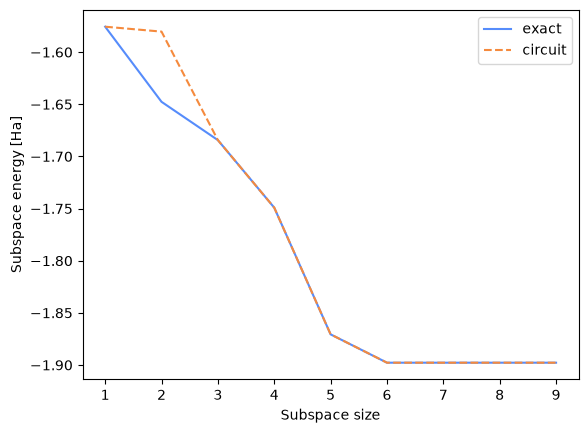

In [51]:
subspace_size = []
exact_energies = []
circuit_energies = []
for i in range(1, 10):
    exact_energies.append(get_sci_energy(configuration_list_exact[:i]))
    circuit_energies.append(get_sci_energy(configuration_list_circuit[:i]))
    subspace_size.append(i)

plt.plot(subspace_size, exact_energies, label='exact')
plt.plot(subspace_size, circuit_energies, '--', label='circuit')
plt.xlabel('Subspace size')
plt.ylabel('Subspace energy [Ha]')
plt.legend()

## Things to explore

- Include circuit compression, removing selected interaction terms from the cluster operator to isolate their effect
- Varying the H-H bond length to explore different correlation regimes.